In [19]:
from oracle_conversions import *
from qiskit.quantum_info import random_unitary,Operator
from qiskit.circuit.library import DiagonalGate
from phase_estimation import *
from search import *
from error_correcting_codes import *
import qiskit


# Miniproject 2: Durr-Hoyer Search

Grover's Algorithm allows us to search for an element in an unordered database, provided that we have a binary oracle that marks the element.

The <i>Durr-Hoyer algorithm</i> is an application of Grover's Algorithm for finding the smallest (or largest) value according to a binary oracle. [source](https://arxiv.org/pdf/quant-ph/9607014)

The algorithm is simple. It consists of repeatedly applying Grover's Algorithm to find a sequence of elements, each of which is better than the previous elements in the sequence. When Grover's Search fails, we surmise that the last element in our sequence is the optimal element.

## Grover Search Background

Here, we gather some background related to searching. The main reference for these search techniques is [source](https://arxiv.org/pdf/quant-ph/0005055).

Let $n\in \mathbb{N}$ be a number of working qubits and let $N=2^n$. Our search space will be the set of $N$ basis states of the Hilbert space of the working qubits. We also have access to $k$ auxillary qubits for some $k\in \mathbb{N}$.

Let $V$ be an $n+k$ qubit circuit, which we call the <i>marking unitary</i>. The associated unitary matrix is a diagonal matrix with $\pm 1$ on the diagonal. The <i>marked</i> elements are basis states $\ket{x}$ of the working qubit system such that $V(\ket{x}\ket{0})= -\ket{x}\ket{0}$. The task of search is to find a marked element. The search may fail and return nothing.

In order to perform Grover's search, we need an $n$-qubit circuit $U$ which we call the <i>initial unitary</i>. Typically, $U$ is the the n-fold tensor product of Hadamard matrices (the Walsh-Hadamard matrix), but we can choose $U$ differently if we have some idea about where the marked elements are to be found.

The <i>Grover operator</i> is the operator $G=-U S_0 U^\dagger V$, where $S_0$ is the $n+k$ qubit diagonal unitary that sends $\ket{0}\mapsto - \ket{0}$ and fixes all other basis states. We apply $U$ to only the working qubits so that the composition is well-defined. Note that the Grover operator is the composition of two reflections, $U S_0 U^\dagger$ and $V$. The first reflection can be thought of as flipping the phase of the initial state, which the second can be thought of as flipping the phases of the marked elements. The product of two reflections is a rotation, so the Grover operator can be viewed as a rotation of the initial vector $U\ket{0}$ toward the subspace spanned by marked elements.

<i>Amplitude Amplification</i> is the process of applying the Grover operator to obtain a state whose amplitude on the marked elements is greater than that of the initial state. This can be viewed as rotating the initial vector toward the subspace spanned by marked elements.

Grover's algorithm consists in applying amplitude amplification several times, then measuring the working qubits. If the initial state's amplitude on the marked qubits is known, then we can calculate the number of times to apply the Grover operator to result in nearly-certain success. This number scales like $\Theta(\sqrt{\frac{N}{t}})$, where $t$ is the number of marked elements. The scaling of the quantum algorithm is better than the number of oracle queries needed clasically, which is $\Theta(\frac{N}{t})$.

In [20]:
qc = QuantumCircuit(2,name="U")
qc.h([0,1])
U = ProbabilityOracleFromCircuit(2,qc) #Our initial unitary
print(U.circuit().draw())

#B = marking_binary_oracle_to_phase_circuit(BinaryOracleFromLinear(3,2))
B = BinaryOracleMark(2,3) #This marks only the input 11
V = marking_binary_oracle_to_phase_circuit(B)
print(V.draw())

search_circuit = grover_search_circuit(U.circuit(),V,0.25)
print(search_circuit.decompose(reps=1).draw(output="text")) 
print(search_circuit.decompose(reps=2).draw(output="text"))

zero_state = Statevector.from_int(0,dims = 2**U.circuit().num_qubits)
initial_state = Statevector.from_int(0, dims = 2**(search_circuit.num_qubits - U.circuit().num_qubits)).tensor(zero_state.evolve(U.circuit()))
final_state = initial_state.evolve(search_circuit)
print(final_state.measure([0,1])[0])


     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     └───┘
         ┌──────────────┐     ┌─────────────────┐
q4511_0: ┤0             ├─────┤0                ├
         │              │     │                 │
q4511_1: ┤1 Binary mark ├─────┤1 Binary mark_dg ├
         │              │┌───┐│                 │
  q4512: ┤2             ├┤ Z ├┤2                ├
         └──────────────┘└───┘└─────────────────┘
     ┌────┐
q_0: ┤0   ├
     │    │
q_1: ┤1 G ├
     │    │
q_2: ┤2   ├
     └────┘
global phase: π
     ┌────┐┌───────┐┌─────┐┌────┐
q_0: ┤0   ├┤0      ├┤0    ├┤0   ├
     │    ││  U_dg ││  S0 ││  U │
q_1: ┤1 V ├┤1      ├┤1    ├┤1   ├
     │    │└───────┘└─────┘└────┘
q_2: ┤2   ├──────────────────────
     └────┘                      
11


## Grover without known probabilities

The standard Grover search requires knowing $t$, the number of marked elements in order to calculate the number of times to apply amplitude amplification.

In our Durr-Hoyer algorithm, we will not know the number of marked elements. Luckily, Grover's algorithm can be modified so that $t$ need not be known. This is Theorem $3$ from our [source](https://arxiv.org/pdf/quant-ph/0005055), and is called <i>Exponential Search</i> in the Durr-Hoyer paper. 

The idea is to guess the number of times to apply the Grover operator. If our guesses are chosen uniformly from a large enough range, then the probability of successfully finding a marked element approaches $\frac{1}{2}$. (See Lemma 2 of [this paper](https://arxiv.org/pdf/quant-ph/9605034).) The approximate size of the range required is the <i>critical value</i>, $m_0$ and is approximately $m_0\approx \sqrt{\frac{N}{t}}$. 

Due to the dependence of $m_0$ on $t$ which is unknown, we cannot simply choose a number $j$ uniformly at random between $0$ and $m_0$ and apply the grover operator $j$ times. So instead, we loop over a counting variable $s=1,2,\dots$ and choose the number $j$ uniformly at random between $0$ and $m=(\frac{6}{5})^s$. We apply the Grover operator $j$ times to the initial state and measure. We continue until the outcome is a marked element or we give up.

Careful analysis reveals that, provided there are $t$ marked elements, the expected number of Grover operators is at most $\frac{9}{2} \frac{N}{2\sqrt{(N-t)t}}\approx \frac{9}{4} \sqrt{\frac{N}{t}}$. (See Theorem $3$ [here](https://arxiv.org/pdf/quant-ph/9605034).)

In [21]:
qc = QuantumCircuit(5)
qc.h(range(5))
initial_unitary = qc
mark= 15
marking_unitary = marking_binary_oracle_to_phase_circuit(BinaryOracleMark(5,15))
outcome = grover_search_without_prob_success(initial_unitary, marking_unitary,prob_failure=0.01)
print(outcome, f"{mark:0{len(outcome)}b}")
assert outcome == f"{mark:0{len(outcome)}b}"

01111 01111


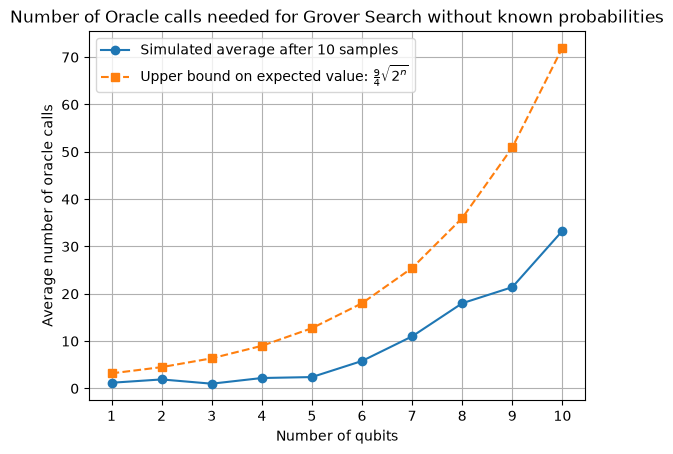

In [22]:
num_samples = 10
qubit_counts = range(1,11)
average_oracle_calls = []
theoretical_oracle_calls = [
    9/4 * math.sqrt(2**n) for n in qubit_counts
]
for num_qubits in qubit_counts:
    B = BinaryOracleMark(num_qubits,0)
    oracle_call_counts = []
    initial_unitary=QuantumCircuit(num_qubits)
    initial_unitary.h(range(num_qubits))
    marking_unitary=marking_binary_oracle_to_phase_circuit(B)
    for _ in range(num_samples):
        _, num_oracle_calls = grover_search_without_prob_success(initial_unitary,marking_unitary,prob_failure = 0,count_grover_calls=True)
        oracle_call_counts.append(num_oracle_calls)
    average_oracle_calls.append(sum(oracle_call_counts)/num_samples)
    #print(num_qubits, sum(oracle_call_counts)/num_samples)


plt.plot(qubit_counts, average_oracle_calls, 'o-', label=f"Simulated average after {num_samples} samples")
plt.plot(qubit_counts, theoretical_oracle_calls, 's--',
         label=r'Upper bound on expected value: $\frac{9}{4}\sqrt{2^n}$')
plt.xlabel('Number of qubits')
plt.ylabel('Average number of oracle calls')
plt.title('Number of Oracle calls needed for Grover Search without known probabilities')
plt.xticks(qubit_counts)
plt.grid(True)
plt.legend()
plt.show()


## Uncertainty and Probabilistic Algorithms

The Durr-Hoyer Algorithm relies on repeated applications of Grover's Algorithm in order to find better and better outcomes, and each application of Grover's Algorithm has a random output and probability of failure. It's pretty clear that both the Durr-Hoyer Algorithm  and Grover's algorithm without known probabilities are correct in the sense that they will eventually return the correct output. However, since "eventually" never arrives, we need a more careful analysis on order to apply the algorithms in practice.


Specifically, we want to know: 
- Given $\epsilon_G>0$, we want to know the number of oracle calls to apply before giving up in Grover's search without known probabilities, in order to achieve a failure rate of at most $\epsilon_G$.
- Given $\epsilon_{DH}>0$, we want to know an acceptable failure rate to pass into our subroutine for Grover's search without known probabilities such that the Dur-Hoyer algorithm fails with probability at most $\epsilon_{DH}$.

A generic approach is to apply linearity of expectation to bound the expected number of oracle calls before the infinite algorithm returns a correct answer, then applying Markov's Bound in order bound the number of oracle calls before we can safely quit the search without incurring more than $\epsilon$ rate of failure. Recall that linearity of expectation states $\mathbb{E}[X+Y] = \mathbb{E}[X]+\mathbb{E}[Y]$ for random variables $X$ and $Y$. Markov's Inequality states that, for any non-negative random variable $X$ and $k>0$, $P(X \geq k \mathbb{E}[X]) \leq \frac{1}{k}$.



### Grover's Algorithm Without Known Probabilities Error Analysis

We already mentioned that Grover's algorithm without known probabilities has an expected number of oracle calls that is about $\frac{9}{4}\sqrt{\frac{N}{t}}$. The analysis applied linearity of expectations by dividing the loop over $s$ into two pieces: those for which the range of random numbers has reached the critical value, and those for which it has not.

We apply Markov's inequality with $\frac{1}{k}=\epsilon_G$ and $X$ being the random variable that counts the number of oracle calls. We obtain that we need approximately $\frac{1}{\epsilon}\sqrt{\frac{N}{t}}\leq\frac{1}{\epsilon}\sqrt{N}$ oracle calls before quitting in order to achieve a failure rate of at most $\epsilon_G$.


### Durr-Hoyer Algorithm Error Analysis

The generic approach of applying linearity of expectation and Markov's Inequality can help us to choose a stopping point for the Dur-Hoyer Algorithm. However, implementation would be tricky, since we would need to aggregate oracle calls used in each subroutine of Grover's Algorithm without known probabilities. 

We follow a simpler approach that uses the union bound to bound the probability that the Durr-Hoyer Algorithm fails. If it fails, then it fails at a particular step. We characterize the steps by a parameter $t$, which is the number of elements that are at least as good as the best element found so far. The probability that the algorithm fails at step $t$ is at most $\epsilon_G$, which we will prescribe. Durr and Hoyer demonstrated by induction that the probability of reaching step $t$ is $\frac{1}{t}$. Therefore, the probability of failure is $\epsilon_{DH}>\sum_{t=1}^{2^n}\frac{\epsilon_{G}}{t} \approx \epsilon_G n\ln(2)$. This analysis shows that we can set $\epsilon_G=\frac{\epsilon_{DH}}{n\ln(2)}$.


In [23]:
B = BinaryOracleHamming(4, 0) #Calculates the Hamming distance to 0 as a binary oracle.
initial_unitary = QuantumCircuit(4)
initial_unitary.h(range(4))

threshold = 5
marking_binary_oracle = compose_binary_oracles(B,BinaryOracleComparator(B.num_output_qubits, threshold, maximize=False))
phase_circuit = marking_binary_oracle_to_phase_circuit(marking_binary_oracle)

print(phase_circuit.decompose(reps=2).draw(output="text",fold=-1))

assert dur_hoyer_search(initial_unitary,B,maximize=False,prob_failure=0.1) == "0000"

         ┌────────┐                                                           ┌───────────┐
q5768_0: ┤0       ├───────────────────────────────────────────────────────────┤0          ├
         │        │                                                           │           │
q5768_1: ┤1       ├───────────────────────────────────────────────────────────┤1          ├
         │        │                                                           │           │
q5768_2: ┤2       ├───────────────────────────────────────────────────────────┤2          ├
         │        │                                                           │           │
q5768_3: ┤3       ├───────────────────────────────────────────────────────────┤3          ├
         │        │   ┌─────────────────┐┌──────────┐┌────────────────────┐   │           │
  q5769: ┤        ├───┤3                ├┤ U(0,0,π) ├┤3                   ├───┤           ├
         │        │   │                 │└──────────┘│                    │   │ 

# Application: Decoding Classical Linear Error Correcting Codes

A (classical) linear error correcting code is defined by a $k\times n$ generating matrix $G$ whose entries are in $\mathbb{F}_2$. Here, $k$ is the number of logical bits and $n$ is the number of physical bits. We assume the matrix has full rank, and that the first $k\times k$ block is the identity matrix. The matrix encodes length-$k$ bitstrings $u$ as the length-$n$ bitstring $uG$. The strings of the form $uG$ are known as <i>codewords</i>.

The Hamming distance between two bitstrings of the same length is the bitcount of the exclusive-or of the bitstrings.

Given an $n$-bit string $x\in \mathbb{F}_2^n$, the task of decoding $x$ is the task of finding a codeword $c$ such that the Hamming distance between $c$ and $x$ is minimal. This is essentially a search over the codewords, so we expect to be able to use Grover's Algorithm or an appropriate variant.

In [24]:
L= ExampleLinearCode()
for row in L.G:
    print([r%2 for r in(row)])
B=L.generation_binary_oracle()
print(B.circuit().draw(output="text"))

for i, x in enumerate([1,2,4,8]):
    print("logical word:",f"{x:0{L.k}b}", "code word:", L.encode_classical(f"{x:0{L.k}b}") )
    assert f"{x:0{L.k}b}"[::-1] + f"{B.apply_oracle(x):0{L.n-L.k}b}" == "".join(str(abs(l)) for l in L.G[i])

for logical_word in range(2**L.k):

    logical_vector = Statevector.from_int(logical_word,dims = 2**L.k)
    aux_vector = Statevector.from_int(0,dims = 2**(L.n-L.k))
    initial_vector = aux_vector.tensor(logical_vector)
    assert L.encode_classical(f"{logical_word:0{L.k}b}") == initial_vector.evolve(B.circuit()).measure()[0][::-1]

[1, 0, 0, 0, 0, 1, 1]
[0, 1, 0, 0, 1, 0, 1]
[0, 0, 1, 0, 1, 1, 0]
[0, 0, 0, 1, 1, 1, 1]
                                                      
q5895_0: ────────────────────────────────■─────────■──
                                         │         │  
q5895_1: ─────────────────■──────────────┼────■────┼──
                          │              │    │    │  
q5895_2: ───────■─────────┼────■─────────┼────┼────┼──
                │         │    │         │    │    │  
q5895_3: ──■────┼────■────┼────┼────■────┼────┼────┼──
         ┌─┴─┐┌─┴─┐  │  ┌─┴─┐  │    │    │    │    │  
q5896_0: ┤ X ├┤ X ├──┼──┤ X ├──┼────┼────┼────┼────┼──
         └───┘└───┘┌─┴─┐└───┘┌─┴─┐  │  ┌─┴─┐  │    │  
q5896_1: ──────────┤ X ├─────┤ X ├──┼──┤ X ├──┼────┼──
                   └───┘     └───┘┌─┴─┐└───┘┌─┴─┐┌─┴─┐
q5896_2: ─────────────────────────┤ X ├─────┤ X ├┤ X ├
                                  └───┘     └───┘└───┘
logical word: 0001 code word: 1000011
logical word: 0010 code word: 0100101
logical wor

## Decoding using the Durr-Hoyer Algorithm

The task of decoding an observed word $y\in \mathbb{F}^n_2$ is a search for a minimum value. We have implemented the encoding circuit and Hamming distance as quantum circuits, so we can combine the two to obtain a Binary Oracle that calculates, given a logical word $u\in \mathbb{F}_2^k$, the Hamming distance between the encoded codeword $uG$ and the observed word $y$.

A naive classical search among the codewords requires $2^k$ steps, since each codeword must be checked.

In contrast, the Durr-Hoyer algorithm can search the codewords in $O(\sqrt{2^k})$ time, which is a quadratic speedup, though it is still exponential in $k$.

This method works well when $k$ is small and $n$ is large, so our codewords are relatively sparse among all $n$-bit strings. This is exactly the regime where decoding can be computationally expensive.

In [25]:
L = ExampleLinearCode()

logical_word = "0010"
print("logical word:", logical_word)
print("encoded word:", L.encode_classical(logical_word))
encoded_word = L.encode_classical(logical_word)
word_with_error = "1100101"
print("word with error:",word_with_error)
quantum_decode= L.decode_quantum(word_with_error)
classical_decode = L.decode_classical(word_with_error)
print("decoded words:",classical_decode,quantum_decode)
assert logical_word == L.decode_classical(encoded_word)
assert classical_decode==quantum_decode

logical word: 0010
encoded word: 0100101
word with error: 1100101
decoded words: 0010 0010
